## Apport du climat par culture et par zone agroclimatique

Ce notebook exécute l'étude préenregistrée dans `docs/research_climate_zones.md`, issue de la troisième suggestion de la revue du projet par une mentore experte. Les variables climatiques n'améliorent pas la prédiction des années futures en moyenne. L'étude cherche si ce résultat cache un apport réel dans certaines cultures ou certaines zones agroclimatiques.

**Précautions**

- Aucun modèle n'est entraîné. L'étude réutilise les prédictions des quatre fenêtres successives de `15_rolling_windows_study.ipynb`, avec et sans variables climatiques.
- Seul le développement est utilisé, et les ensembles de test ne sont pas consultés.

**Préalable**

Le notebook suppose les prédictions de `python -m src.recherche.fenetres_temporelles` calculées et le magasin climatique construit. Il s'exécute en une minute environ.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.features.climat import DOSSIER_MAGASIN
from src.models.bilan import part_expliquee_climat
from src.recherche.fenetres_temporelles import developpement_regional, lire
from src.recherche.zones_climatiques import (
    CLASSES_ARIDITE, apport_par_strate, climat_annuel_mailles, cultures_principales, indice_aridite_zones,
    predictions_avec_strates,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
developpement = developpement_regional()
aridite = indice_aridite_zones(pd.read_csv(DOSSIER_MAGASIN / "poids_regional.csv"), climat_annuel_mailles())
lignes = predictions_avec_strates(developpement, lire(developpement), aridite)
cultures = cultures_principales(lignes)

### 1. Tests unitaires

Les tests de l'étude vérifient les seuils d'aridité, la pondération des mailles en présence de valeurs manquantes et le calcul de l'apport par strate.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 116 tests in 13.329s', '', 'OK']


### 2. Zones agroclimatiques

L'indice d'aridité de chaque zone est le rapport entre la pluie IMERG annuelle moyenne et l'évapotranspiration de référence annuelle moyenne, sur 2001 à 2016. Les classes suivent les seuils du Programme des Nations unies pour l'environnement.

In [3]:
display(aridite[["pluie_annuelle", "et0_annuelle", "indice_aridite"]].describe().round(2))
zones_dev = developpement.drop_duplicates("GDAM_ID").assign(classe=lambda d: d["GDAM_ID"].map(aridite["classe_aridite"]))
repartition = zones_dev.groupby("classe").agg(zones=("GDAM_ID", "size"), pays=("country", "nunique"),
                                            principaux_pays=("country", lambda s: ", ".join(s.value_counts().index[:4])))
display(repartition.reindex(CLASSES_ARIDITE))
print("Lignes évaluées dans les fenêtres par classe :", lignes["classe_aridite"].value_counts().reindex(CLASSES_ARIDITE).to_dict())
print("Cultures étudiées :", cultures)

,pluie_annuelle,et0_annuelle,indice_aridite
count,1682.00,1682.00,1682.00
mean,1016.25,1850.66,0.62
std,472.41,443.15,0.38
min,2.98,1072.12,0.00
25%,704.01,1488.76,0.35
50%,1026.06,1784.01,0.57
75%,1285.01,2091.13,0.83
max,3052.14,3291.22,2.55


,zones,pays,principaux_pays
classe,,,
hyperaride,37,7,"Egypt, Algeria, Sudan, Niger"
aride,142,17,"Somalia, Niger, Morocco, Senegal"
semi_aride,338,32,"Burkina Faso, Mozambique, Mali, Zambia"
subhumide_seche,198,26,"Mozambique, Zambia, Ethiopia, Ghana"
humide,543,25,"Cameroon, Uganda, Ghana, Benin"


Lignes évaluées dans les fenêtres par classe : {'hyperaride': 179, 'aride': 4959, 'semi_aride': 17025, 'subhumide_seche': 12171, 'humide': 24513}
Cultures étudiées : ['Maize', 'Sorghum', 'Groundnut', 'Rice', 'Cowpea', 'Millet', 'Sweet potato']


**Constat**

- L'indice d'aridité médian des zones vaut 0,57, pour une pluie annuelle médiane de 1 026 mm et une évapotranspiration de 1 784 mm.
- Parmi les zones du développement, 37 sont hyperarides, 142 arides, 338 semi-arides, 198 subhumides sèches et 543 humides. Les zones arides se trouvent surtout en Somalie, au Niger, au Maroc et au Sénégal, les zones humides au Cameroun, en Ouganda, au Ghana et au Bénin.
- La classe hyperaride ne compte que 179 lignes évaluées dans les fenêtres et n'est pas analysée, le plan exigeant 1 000 lignes par strate.

**Analyse**

Les classes retrouvent la géographie connue de l'aridité africaine, du Sahel et de la Corne de l'Afrique aux zones humides du golfe de Guinée et des Grands Lacs.

### 3. Apport du climat à la prédiction des années futures

L'apport du climat est la différence entre l'erreur du modèle privé de climat et celle du modèle retenu, positive lorsque le climat aide, sur les lignes des quatre fenêtres. Les intervalles de confiance à 95 % sont obtenus par bootstrap des groupes du protocole.

In [4]:
par_classe = apport_par_strate(lignes, "classe_aridite").reindex([c for c in CLASSES_ARIDITE])
par_classe = par_classe.dropna(how="all")
display(par_classe.round(4))
par_culture = apport_par_strate(lignes[lignes["crop"].isin(cultures)], "crop")
display(par_culture.round(4))

,lignes,pays,mae_log,competence,apport_climat,apport_bas,apport_haut
strate,,,,,,,
aride,4959.0,12.0,0.3840,0.1050,-0.0014,-0.0081,0.0051
semi_aride,17025.0,25.0,0.3920,0.1189,-0.0033,-0.0068,0.0003
subhumide_seche,12171.0,21.0,0.3404,0.1593,-0.0080,-0.0115,-0.0043
humide,24513.0,22.0,0.3400,0.0897,-0.0053,-0.0087,-0.0015


,lignes,pays,mae_log,competence,apport_climat,apport_bas,apport_haut
strate,,,,,,,
Cowpea,4128,21,0.4074,0.2017,-0.0038,-0.0093,0.0020
Groundnut,4964,27,0.3284,0.1064,-0.0028,-0.0072,0.0019
Maize,7312,30,0.2946,0.1098,-0.0045,-0.0083,-0.0002
Millet,4008,23,0.3169,0.1178,0.0028,-0.0022,0.0091
Rice,4188,28,0.3627,0.1045,-0.0032,-0.0083,0.0019
Sorghum,5532,26,0.3241,0.1264,-0.0033,-0.0069,0.0006
Sweet potato,3489,20,0.3806,0.0540,-0.0061,-0.0116,-0.0005


**Constat**

- L'apport du climat n'est significativement positif dans aucune classe d'aridité. Il vaut -0,0014 en zone aride et -0,0033 en zone semi-aride, sans être significatif, puis -0,0080 en zone subhumide sèche et -0,0053 en zone humide, significativement négatif.
- Parmi les sept cultures étudiées, seul le mil présente un apport positif, de 0,0028, sans être significatif. L'apport est significativement négatif pour le maïs et la patate douce.

**Analyse**

Le climat ne permet de mieux prédire les années futures dans aucune zone ni pour aucune culture. Il est même défavorable dans les zones subhumides et humides, où la pluie limite moins les rendements.

### 4. Part de la variation annuelle expliquée par le climat

La part expliquée est calculée comme dans `docs/modeling.md`. Le logarithme du rendement et les variables climatiques sont débarrassés, série par série, de leur moyenne et de leur tendance, sur les séries d'au moins dix récoltes postérieures à 2000. Calculée sur les données ajustées, elle majore la part prévisible.

In [5]:
variables = ["pluie_cumul", "bilan_hydrique", "sequence_seche_max", "tmax_moyenne", "degres_jours_30", "dpv_moyen",
             "rayonnement_moyen", "pluie_jours"]
avec_classe = developpement.assign(classe_aridite=developpement["GDAM_ID"].map(aridite["classe_aridite"]))
strates = {c: (lambda d, c=c: (d["classe_aridite"] == c).to_numpy()) for c in CLASSES_ARIDITE}
strates["aride_et_semi_aride"] = lambda d: d["classe_aridite"].isin(["aride", "semi_aride"]).to_numpy()
strates.update({c: (lambda d, c=c: (d["crop"] == c).to_numpy()) for c in cultures})
parts = part_expliquee_climat(avec_classe, variables, strates=strates)
display(parts.round(3))

,lignes,series,part_expliquee,ecart_type_anomalie
aride,3447.0,252.0,0.063,0.392
semi_aride,14067.0,998.0,0.030,0.416
subhumide_seche,10396.0,776.0,0.018,0.352
humide,16449.0,1227.0,0.009,0.303
aride_et_semi_aride,17514.0,1250.0,0.032,0.412
Maize,6826.0,480.0,0.035,0.298
Sorghum,4838.0,351.0,0.035,0.351
Groundnut,3432.0,240.0,0.068,0.322
Rice,3401.0,242.0,0.025,0.341
Cowpea,3242.0,231.0,0.041,0.528


**Constat**

- La part de la variation annuelle expliquée par le climat décroît avec l'humidité, de 6,3 % en zone aride à 3,0 % en zone semi-aride, 1,8 % en zone subhumide sèche et 0,9 % en zone humide.
- Parmi les cultures, elle atteint 6,8 % pour l'arachide et 5,3 % pour le mil, contre 2,5 % pour le riz.

**Analyse**

Le gradient est celui qu'attend l'agronomie. Là où la pluie est rare, sa variation d'une année à l'autre pèse davantage sur les rendements, et les cultures des zones sèches, comme le mil et l'arachide, y sont les plus sensibles. Le signal climatique existe donc, mais il reste faible, même dans les zones arides.

### 5. Verdict des hypothèses

Les verdicts suivent les énoncés de la section 6 du plan. Pour H2 et H3, les classes aride et semi-aride sont réunies.

In [6]:
seches = lignes.assign(groupe_aridite=np.where(lignes["classe_aridite"].isin(["aride", "semi_aride"]), "aride_et_semi_aride",
                                               lignes["classe_aridite"]))
par_groupe = apport_par_strate(seches, "groupe_aridite")
apport_sec, apport_humide = par_groupe.loc["aride_et_semi_aride", "apport_climat"], par_groupe.loc["humide", "apport_climat"]
verdicts = pd.DataFrame([
    {"hypothese": "H1", "mesure": int((par_classe["apport_bas"] > 0).sum()), "confirmee": bool((par_classe["apport_bas"] > 0).any())},
    {"hypothese": "H2", "mesure": apport_sec - apport_humide, "confirmee": apport_sec > apport_humide},
    {"hypothese": "H3", "mesure": parts.loc["aride_et_semi_aride", "part_expliquee"] - parts.loc["humide", "part_expliquee"],
     "confirmee": parts.loc["aride_et_semi_aride", "part_expliquee"] > parts.loc["humide", "part_expliquee"]},
    {"hypothese": "H4", "mesure": int((par_culture["apport_bas"] > 0).sum()), "confirmee": bool((par_culture["apport_bas"] > 0).any())},
])
display(par_groupe.loc[["aride_et_semi_aride", "humide"]].round(4))
display(verdicts.round(4))

,lignes,pays,mae_log,competence,apport_climat,apport_bas,apport_haut
strate,,,,,,,
aride_et_semi_aride,21984,26,0.3902,0.1158,-0.0028,-0.0063,0.0007
humide,24513,22,0.3400,0.0897,-0.0053,-0.0087,-0.0015


,hypothese,mesure,confirmee
0,H1,0.0000,False
1,H2,0.0024,True
2,H3,0.0234,True
3,H4,0.0000,False


**Constat**

- **H1 est réfutée.** L'apport du climat n'est significativement positif dans aucune classe d'aridité.
- **H2 est confirmée de justesse.** L'apport vaut -0,0028 dans les classes aride et semi-aride réunies et -0,0053 dans la classe humide. Il est moins défavorable en zone sèche, mais n'y est pas positif, et le plan ne prévoyait pas de tester la significativité de cette différence.
- **H3 est confirmée.** La part expliquée vaut 3,2 % dans les classes aride et semi-aride réunies, contre 0,9 % dans la classe humide.
- **H4 est réfutée.** L'apport du climat n'est significativement positif pour aucune des sept cultures.

### 6. Figure

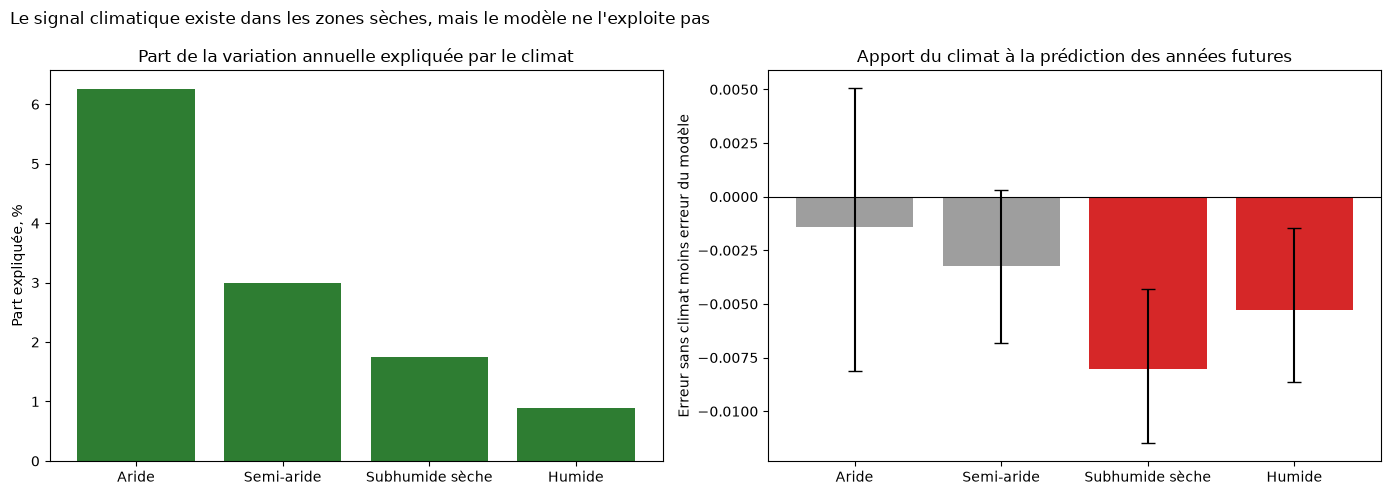

In [7]:
ordre = [c for c in CLASSES_ARIDITE if c in parts.index and c in par_classe.index]
noms = {"hyperaride": "Hyperaride", "aride": "Aride", "semi_aride": "Semi-aride", "subhumide_seche": "Subhumide sèche",
        "humide": "Humide"}
figure, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))
gauche.bar([noms[c] for c in ordre], parts.loc[ordre, "part_expliquee"] * 100, color="#2e7d32")
gauche.set_title("Part de la variation annuelle expliquée par le climat")
gauche.set_ylabel("Part expliquée, %")
x = np.arange(len(ordre))
valeurs = par_classe.loc[ordre]
droite.bar(x, valeurs["apport_climat"], color=np.where(valeurs["apport_bas"] > 0, "#2e7d32",
                                                        np.where(valeurs["apport_haut"] < 0, "#d62728", "#9e9e9e")))
droite.errorbar(x, valeurs["apport_climat"], yerr=[valeurs["apport_climat"] - valeurs["apport_bas"],
                valeurs["apport_haut"] - valeurs["apport_climat"]], fmt="none", ecolor="black", capsize=5)
droite.axhline(0, color="black", lw=0.8)
droite.set_xticks(x, [noms[c] for c in ordre])
droite.set_title("Apport du climat à la prédiction des années futures")
droite.set_ylabel("Erreur sans climat moins erreur du modèle")
figure.suptitle("Le signal climatique existe dans les zones sèches, mais le modèle ne l'exploite pas", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(RACINE / "reports" / "figures" / "climat_aridite.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

La figure met en regard les deux mesures. La part expliquée par le climat croît nettement avec l'aridité, alors que son apport à la prédiction reste nul ou défavorable dans toutes les classes.

### 7. Synthèse

**Résultats**

| Classe d'aridité | Part expliquée par le climat | Apport à la prédiction | Significatif |
|---|---:|---:|---|
| Aride | 6,3 % | -0,0014 | Non |
| Semi-aride | 3,0 % | -0,0033 | Non |
| Subhumide sèche | 1,8 % | -0,0080 | Oui, défavorable |
| Humide | 0,9 % | -0,0053 | Oui, défavorable |

**Interprétation**

Le signal climatique existe, et il est d'autant plus fort que la zone est sèche, comme l'attend l'agronomie. Mais le modèle ne l'exploite pour prédire les années futures dans aucune zone. Plusieurs causes, que cette étude ne distingue pas, peuvent l'expliquer. Le signal reste faible, au plus 6 % de la variation même en zone aride. Les douze variables climatiques décrivent aussi le lieu, et le modèle peut s'en servir pour reconnaître les régions plutôt que pour apprendre une réponse au climat. Enfin, les arbres apprennent des seuils propres aux années d'entraînement, qui se transposent mal aux années suivantes.

**Pistes**

- Représenter le climat par ses anomalies par rapport à la normale de chaque zone, pour le séparer du lieu.
- Réduire le climat à quelques variables pertinentes en zone sèche, comme la pluie de saison et la plus longue séquence sèche, avec des contraintes de monotonie.
- Restreindre l'usage du climat aux zones arides et semi-arides, où le signal existe.

**Limites**

- L'indice d'aridité ne résume que le climat moyen, sans les sols, le relief ni l'irrigation.
- Cultures et classes ne sont pas indépendantes.
- Comparer plusieurs strates multiplie les tests, ce qui invite à la prudence sur tout résultat isolé.